# Virtual iEEG

The work by [Grova et al. (2016)](https://onlinelibrary.wiley.com/doi/epdf/10.1002/hbm.23127) describes a methodology to compare source reconstruction with intracranial EEG and to evaluate source reconstruction in vivo. The authors project the source-reconstructed data, using a simplified forward model, onto the channel positions of the iEEG. They then compute four metrics to quantitatively evaluate the reconstruction:

1. Spatial correlation
2. Euclidean distance between maxima
3. Spatial dispersion
4. Ratio of spurious activity

This notebook implements the method proposed by Grova et al. on other datasets.

## 🧪 - Experiment setup
- `src`: Source spaces
- `i-ave`: Average intracranial recording
- `wcset`: Source estimate using wCSET method
- `sloreta`: Source estimate using sLORETA method

In [1]:
# imports
import mindmap as mm

# reader
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("intra-12")

# data
src = sr.load("src")
ieeg = sr.load("i-ave", task="spk")
wcset = sr.load("stc", desc="wcset")
sloreta = sr.load("stc", desc="sloreta")

## 🧬 - Data Processing
Virtual electrodes: Project source reconstruction to iEEG channel positions.
`v_wcset`: virtual electrodes estimated using wCSET output
`v_sloreta`: virtual electrodes estimated using sLORETA output

In [2]:
v_wcset = mm.analysis.eeg.compute_virtual_ieeg(
    src,
    wcset,
    ieeg,
    conductivity = 0.25,
    threshold = 0.003,
)

v_sloreta = mm.analysis.eeg.compute_virtual_ieeg(
    src,
    sloreta,
    ieeg,
    conductivity = 0.25,
    threshold = 0.003,
)

# normalize data for visualizations
ieeg_norm = mm.analysis.eeg.normalize_evoked(ieeg, "global", "zscore")
v_wcset_norm = mm.analysis.eeg.normalize_evoked(v_wcset, "global", "zscore")
v_sloreta_norm = mm.analysis.eeg.normalize_evoked(v_sloreta, "global", "zscore")

#### 📊 - Visualization

/tmp/ipykernel_49626/43824775.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ).show()


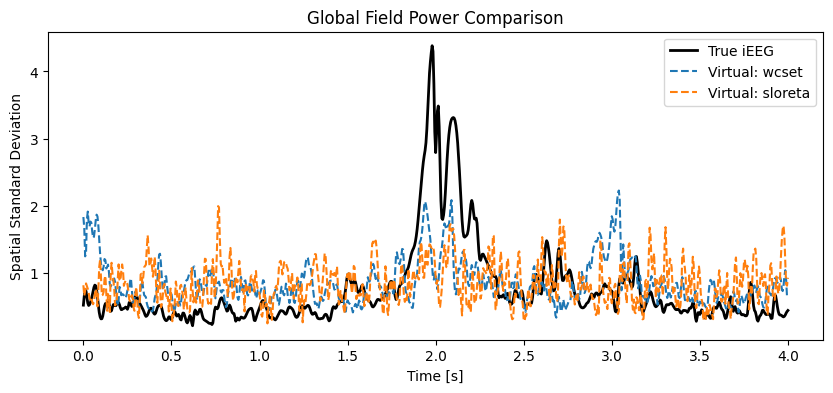

In [3]:
# plot the global field power (gfp)
mm.viz.plot_gfp_comparison(
    ieeg_norm,
    dict_of_evoked_est = {
        "wcset": v_wcset_norm,
        "sloreta": v_sloreta_norm,
    }
).show()

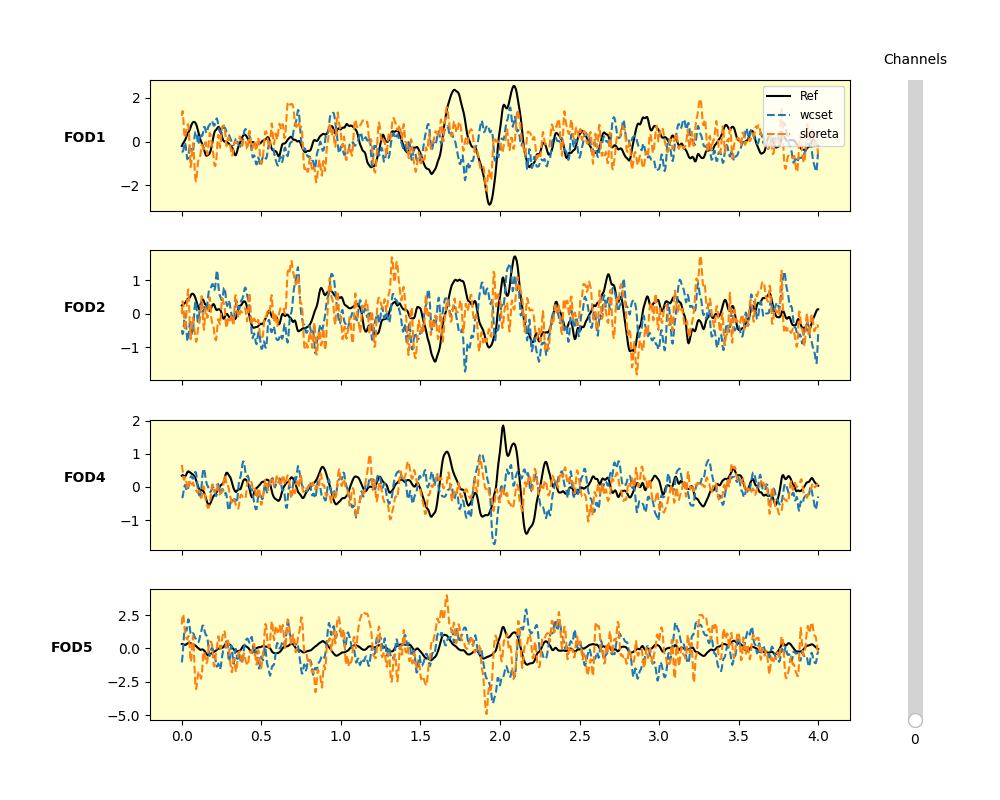

In [4]:
%matplotlib widget

# estimate spike generation extent zone and spurious zone
extent_mask = mm.core.get_spike_extent_mask(
    ieeg.data.T, 
    perc_max_amp=0.7
)

spurious_mask = mm.core.get_spurious_mask(
    extent_mask,
    mm.analysis.eeg.get_ch_positions(ieeg),
    spurious_dist=0.01
)

# plot individual channels
_ = mm.viz.plot_channel_grid(ieeg_norm, {"wcset":v_wcset_norm, "sloreta":v_sloreta_norm}, extent_mask, spurious_mask)
